# Exploratory Data Analysis
The goal of this notebook is to understand the data well enough to decide what preprocessing is needed.

**Dataset:** [Diabetes 130-US Hospitals (1999-2008)](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008),
about 100k hospital encounters of diabetic patients.

**Task:** predict whether a patient is readmitted **in less than 30 days** after discharge.

## Import libraries

In [49]:
import sys

from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.append("..")
from src.data import load_data
from src.visualization import readmission_rate_by

## Load data

In [50]:
dataset, _, _ = load_data()

/home/isabel/Master_IA/XAI/xai-diabetes-readmission/.venv/lib/python3.13/site-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


In [51]:
df_orig = dataset.data.original
df = df_orig.copy()

## First look and data quality

In [52]:
df.head(3)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO


In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [54]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


### Metadata and variable descriptions

In [55]:
dataset["metadata"]

{'uci_id': 296,
 'name': 'Diabetes 130-US Hospitals for Years 1999-2008',
 'repository_url': 'https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008',
 'data_url': 'https://archive.ics.uci.edu/static/public/296/data.csv',
 'abstract': 'The dataset represents ten years (1999-2008) of clinical care at 130 US hospitals and integrated delivery networks. Each row concerns hospital records of patients diagnosed with diabetes, who underwent laboratory, medications, and stayed up to 14 days. The goal is to determine the early readmission of the patient within 30 days of discharge.\nThe problem is important for the following reasons. Despite high-quality evidence showing improved clinical outcomes for diabetic patients who receive various preventive and therapeutic interventions, many patients do not receive them. This can be partially attributed to arbitrary diabetes management in hospital environments, which fail to attend to glycemic control. Failure to provide

In [56]:
dataset["variables"].head(3)

,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,NaN,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,NaN,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes


**Features**
The dataset has information about demographics, admission type and source, discharge disposition, length of stay, number of lab tests, procedures, medications, prior outpatient/emergency/inpatient visits, ICD-9 diagnosis codes, A1C and glucose results, and about 20 individual drug columns.

### Duplicates

In [57]:
print("Duplicated encounter_id:", df["encounter_id"].duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())

Duplicated encounter_id: 0
Fully duplicated rows: 0


In [58]:
print("Unique pacients:", df["patient_nbr"].nunique())

Unique pacients: 71518


In [59]:
print(df["gender"].value_counts(dropna=False), end="\n\n")
print(df["race"].value_counts(dropna=False))

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64


## Target variable
The target variables is defined in the documentation as: *days to inpatient readmission. `<30` if the patient was
readmitted in less than 30 days, `>30` if readmitted after more than 30 days,
and `NO` if there is no record of readmission.*

I will frame it as binary classification: **positive class = `<30`**.

In [60]:
df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [61]:
TARGET = "readmitted"
df[TARGET] = (df_orig["readmitted"] == "<30").astype(int)
df[TARGET].describe()

count    101766.000000
mean          0.111599
std           0.314874
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           1.000000
Name: readmitted, dtype: float64

In [62]:
print(f"Positive rate (raw data): {df[TARGET].mean():.2%}")

Positive rate (raw data): 11.16%


**Takeaway:** the data is highly imbalanced (around 11% positives). A trivial model
that always predicts "no readmission" would reach about 89% accuracy, so **accuracy is
useless here**. We will use ROC-AUC, PR-AUC, recall/precision at a chosen threshold and
calibration

## Missing values analysis

In [63]:
(df.isna().mean() * 100).loc[lambda x: x > 0]

race                  2.233555
weight               96.858479
payer_code           39.557416
medical_specialty    49.082208
diag_1                0.020636
diag_2                0.351787
diag_3                1.398306
max_glu_serum        94.746772
A1Cresult            83.277322
dtype: float64

**Interpretation, column by column:**

| Column | Missing | Decision |
|---|---|---|
| `weight` | ~97% | **Drop**: too sparse to be useful. |
| `max_glu_serum` | ~95% | Not a true missing value. According to the documentation, no value means **the test was not taken**. Encode as its own category (`"Not tested"`). |
| `A1Cresult` | ~83% | Same logic: `"Not tested"` category. Whether the test was done is itself clinically meaningful. |
| `payer_code` | ~40% | Who pays should not influence clinical risk. If it does, it is a proxy for socioeconomic status. Keep for now as `"Unknown"` and **test it with SHAP** instead of dropping it blindly. |
| `medical_specialty` | ~49% | Specialty of the admitting physician. Same approach: keep as `"Unknown"`, evaluate its importance later, and drop it if it only adds noise. |
| `race` (~2%), `diag_1/2/3` (<2%) | small | Impute as `"Unknown"` / `"Missing"`. |

### Handling missing values

Drop weight column

In [64]:
df = df.drop(columns=["weight"])

Replace "not true" missing values by their placeholder

In [65]:
for col in ["max_glu_serum", "A1Cresult"]:
    df[col] = df[col].fillna("Not tested")

for col in ["payer_code", "medical_specialty", "diag_1", "diag_2", "diag_3", "race"]:
    df[col] = df[col].fillna("Unknown")

## Avoiding data leakage

### Leakage 1: Repeated patients
A patient can be admitted to the hospital multiple times and can therefore appear several times in the dataset with different encounter_id. A later encounter of a patient is evidence that the earlier one was followed by a readmission and would be data leakage.

**Fix:** keep only the first encounter of each patient. This way, every row will be a different patient and a standard split will not leak patient information between train and test.

Encounters: 101,766 | Unique patients: 71,518
Patients with more than one encounter: 23.5%


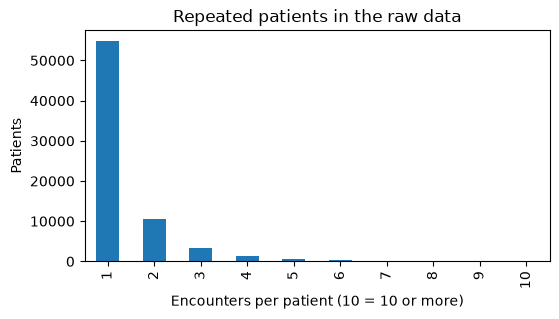

In [66]:
enc_per_patient = df.groupby("patient_nbr").size()
print(f"Encounters: {len(df):,} | Unique patients: {df['patient_nbr'].nunique():,}")
print(f"Patients with more than one encounter: {(enc_per_patient > 1).mean():.1%}")

fig, ax = plt.subplots(figsize=(6, 3))
enc_per_patient.clip(upper=10).value_counts().sort_index().plot.bar(ax=ax)
ax.set_xlabel("Encounters per patient (10 = 10 or more)")
ax.set_ylabel("Patients")
ax.set_title("Repeated patients in the raw data")
plt.show()

In [67]:
n_before = len(df)
df = df.sort_values("encounter_id").drop_duplicates("patient_nbr", keep="first")

print(f"Rows removed: {n_before - len(df):,} -> {len(df):,} rows (one per patient)")
print(f"Positive rate after dedup: {df[TARGET].mean():.2%}")

Rows removed: 30,248 -> 71,518 rows (one per patient)
Positive rate after dedup: 8.80%


### Leakage 2: Patients who died or went to hospice
The variable discharge_disposition_id encondes why the encounter of a patient ended. What each ID means is explained in the `IDS_mapping.csv` file that is provided in the web (https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008).

Some encounters end with the patient expired (died in hospital, discharge_disposition_id in [11, 19, 20, 21]). These patients cannot be readmitted, so their target value will be `0` by construction. If we keep the patients who have passed away, then the model will learn that some discharge codes mean no readmission, which is true but useless and will distort the metrics and explanations.

**Fix:** drop encounters with `discharge_disposition_id` in [11, 19, 20, 21]

In [68]:
EXPIRED_IDS = [11, 19, 20, 21]

is_dead = df["discharge_disposition_id"].isin(EXPIRED_IDS)
print(df[is_dead].groupby("discharge_disposition_id")[TARGET].agg(positive_rate="mean", rows="size"))

                          positive_rate  rows
discharge_disposition_id                     
11                                  0.0  1077
19                                  0.0     6
20                                  0.0     1


In [69]:
n_before = len(df)
df = df.loc[~is_dead]

print(f"Rows removed: {n_before - len(df):,} -> {len(df):,} rows")
print(f"Positive rate after cleaning: {df[TARGET].mean():.2%}")

Rows removed: 1,084 -> 70,434 rows
Positive rate after cleaning: 8.93%


All EDA from here on uses the leak-free data:

In [70]:
df_clean = df.copy()
df_clean.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,readmitted
count,7.043400e+04,7.043400e+04,70434.000000,70434.000000,70434.000000,70434.000000,70434.000000,70434.000000,70434.000000,70434.000000,70434.000000,70434.000000,70434.000000,70434.000000
mean,1.569154e+08,5.498784e+07,2.105162,3.478434,5.641125,4.283641,42.916631,1.422111,15.666752,0.280092,0.103856,0.176861,7.231195,0.089346
std,1.004168e+08,3.947983e+07,1.508917,5.227025,4.165189,2.939722,19.902673,1.754910,8.282757,1.064703,0.511163,0.603256,1.999309,0.285245
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,8.146410e+07,2.335727e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000,0.000000
50%,1.441561e+08,4.801833e+07,1.000000,1.000000,7.000000,3.000000,44.000000,1.000000,14.000000,0.000000,0.000000,0.000000,8.000000,0.000000
75%,2.156215e+08,8.751610e+07,3.000000,3.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,0.000000,9.000000,0.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,42.000000,12.000000,16.000000,1.000000


## Feature analysis

In [71]:
ID_COLS = ["encounter_id", "patient_nbr"]
DEMOGRAPHIC_COLS = ["race", "gender", "age"]

LAB_COLS = ["A1Cresult", "max_glu_serum"]
ADMIN_COLS = ["payer_code", "medical_specialty"]
MED_SUMMARY_COLS = ["change", "diabetesMed"]

DRUG_COLS = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone",
    "metformin-pioglitazone",
]

DIAG_COLS = ["diag_1", "diag_2", "diag_3"]

NUMERIC_COLS = [
    "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
]
CODED_ID_COLS = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]

### Numeric features

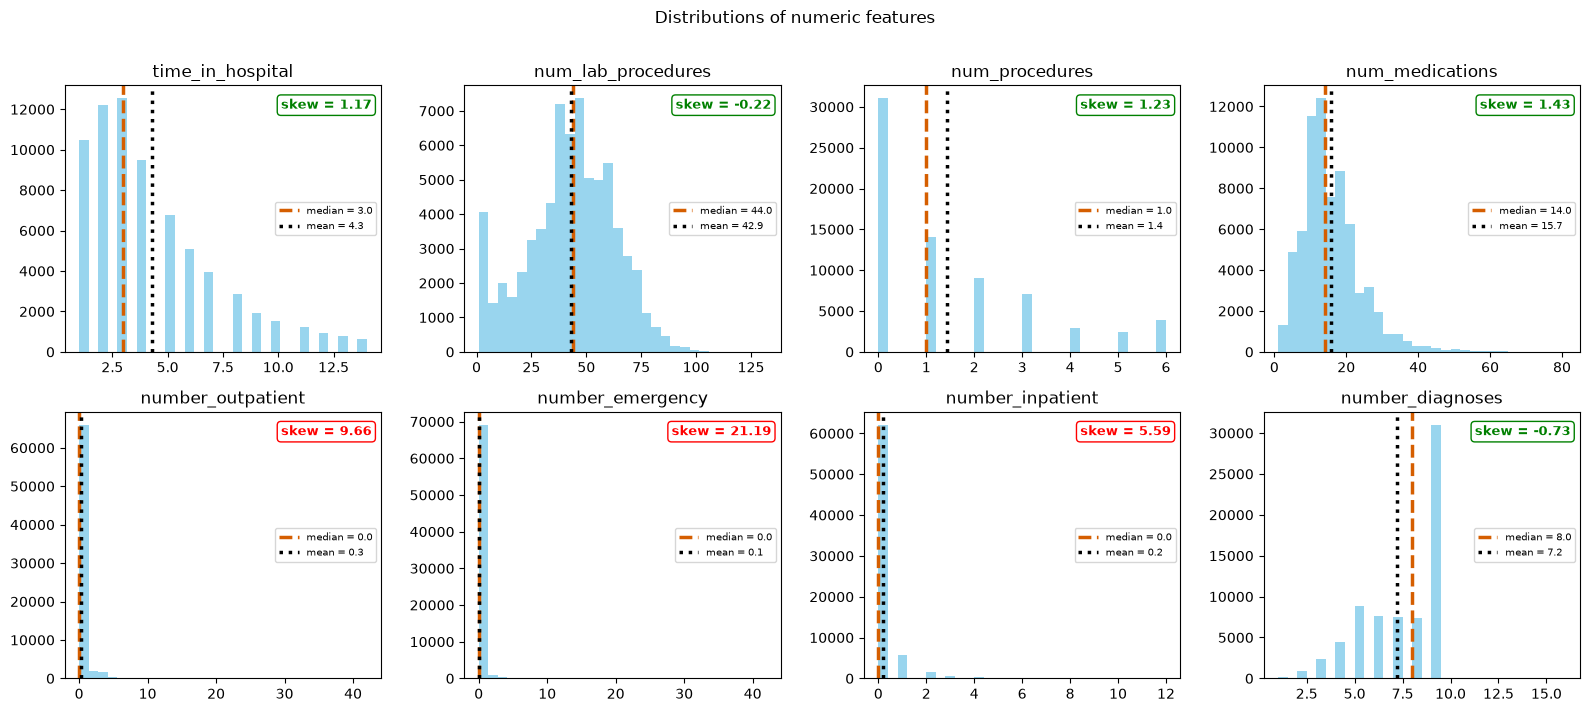

In [72]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    s = df_clean[col]
    sk, needs_log = s.skew(), abs(s.skew()) > 5
    c = "red" if needs_log else "green"
    ax.hist(s, bins=30, color="skyblue", alpha=0.85)
    ax.axvline(s.median(), color="#D55E00", ls="--", lw=2.5, label=f"median = {s.median():.1f}")
    ax.axvline(s.mean(), color="black", ls=":", lw=2.5, label=f"mean = {s.mean():.1f}")
    ax.text(0.97, 0.95, f"skew = {sk:.2f}", transform=ax.transAxes, ha="right", va="top",
            fontsize=9, fontweight="bold", color=c, bbox=dict(boxstyle="round", fc="white", ec=c))
    ax.set_title(col)
    ax.legend(fontsize=7, loc="center right")
fig.suptitle("Distributions of numeric features", y=1.01)
plt.tight_layout()
plt.show()

The features `number_outpatient`, `number_emergency`, `number_inpatient` are very skewed towards the right. Tree models can handle this but for linear models and SHAP estimations this needs to be taken into account

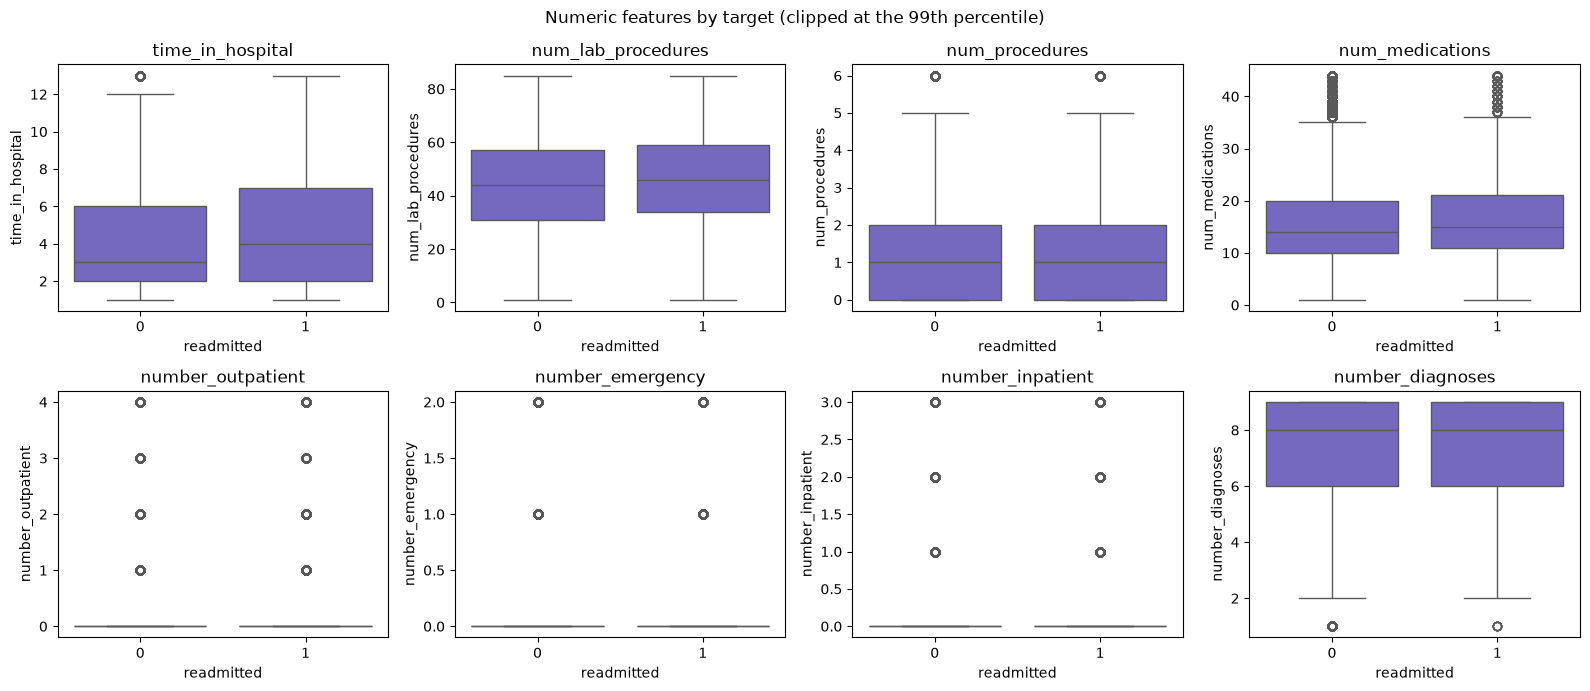

In [73]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    s = df_clean[col].clip(upper=df_clean[col].quantile(0.99))
    sns.boxplot(data=df_clean.assign(**{col: s}), x=TARGET, y=col, ax=ax, color="slateblue")
    ax.set_title(col)
plt.suptitle("Numeric features by target (clipped at the 99th percentile)")
plt.tight_layout()
plt.show()

The shifts are modest, which fits a weak-signal problem

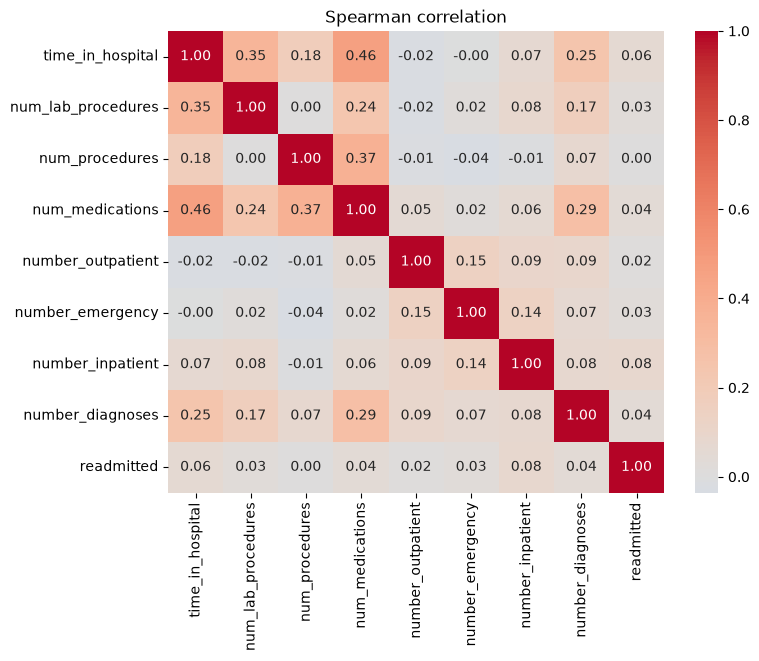

In [74]:
# Correlation between numeric features
corr = df_clean[NUMERIC_COLS + [TARGET]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Spearman correlation")
plt.show()

The numerical variables are not too correlated. The strongest correlation are between time_in_hospital with num_lab_procedures, num_procedures and num_medications which makes sense because if a patient has to stay longer in hospital then they will probably need more procedures and treatment to get better.

### Categorical features

#### Demographic features

##### Groups sizes

In [75]:
for col in DEMOGRAPHIC_COLS:
    tab = df_clean.groupby(col)[TARGET].agg(patients="size", positive_rate="mean", positives="sum").sort_values("patients", ascending=False)
    print(f"\n{tab}")


                 patients  positive_rate  positives
race                                               
Caucasian           52663       0.091449       4816
AfricanAmerican     12692       0.086117       1093
Unknown              1921       0.073399        141
Hispanic             1506       0.081009        122
Other                1161       0.068906         80
Asian                 491       0.083503         41

                 patients  positive_rate  positives
gender                                             
Female              37468       0.089943       3370
Male                32963       0.088675       2923
Unknown/Invalid         3       0.000000          0

          patients  positive_rate  positives
age                                         
[70-80)      17889       0.101962       1824
[60-70)      15763       0.089704       1414
[50-60)      12368       0.071071        879
[80-90)      11267       0.106594       1201
[40-50)       6840       0.074123        507
[30-40

I will drop the 3 cases where the gender is Unknown/ Invalid because it will only add noise and it doesn't have a signal related to the positive readmission class.

In [76]:
df_clean[df_clean["gender"] == "Unknown/Invalid"]

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
30506,98634858,100695042,Other,Unknown/Invalid,[70-80),3,1,1,1,Unknown,...,No,No,No,No,No,No,No,Ch,Yes,0
75551,226864668,60524946,Unknown,Unknown/Invalid,[60-70),1,1,7,1,CP,...,No,No,No,No,No,No,No,No,No,0
82573,257364294,78119847,Unknown,Unknown/Invalid,[70-80),1,22,7,8,CP,...,No,No,No,No,No,No,No,Ch,Yes,0


Small groups will lead to noisy fairness metrics. Therefore, ...

##### Readmission rates

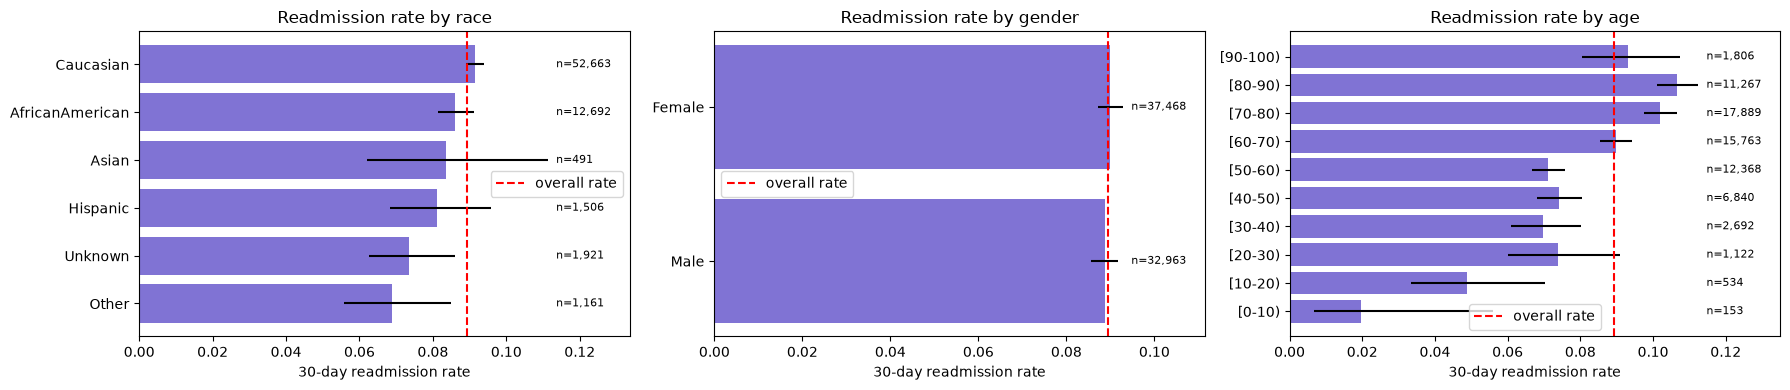

In [77]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, DEMOGRAPHIC_COLS):
    if "age" == col:
        sort_by = "index"
    else:
        sort_by = "rate"
    readmission_rate_by(df_clean, col, ax=ax, sort_by=sort_by)
plt.tight_layout()
plt.show()

When looking at the readmisssion rate by race, it also doesn't look to be biased. Caucasians have a higher readmission rate but they are also the group with the highest number of patients; African Americans are the group with the second highest readmissions but are as well the second largets group of patients. 

The target variable does not appear to be biased by gender as the overall rate of readmission is very similar for both mean and women.

Readmission rate increases as patients get older. The slight reduction for the age group of patients who are [90-100) years old is due to the significant reduction in number of patients for that age group and probably also because at those ages the likelihood of dying is much higher

##### Analysis of possible proxis for race

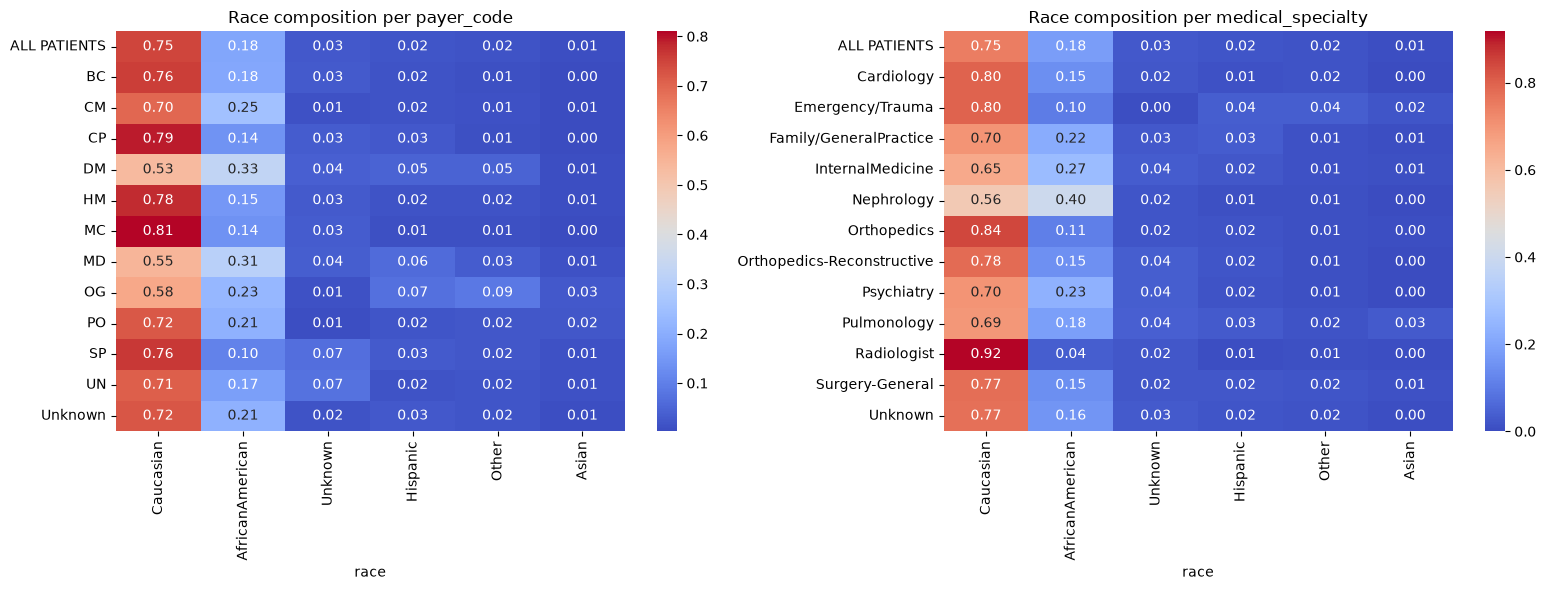

In [78]:
race = df_clean["race"]
overall = race.value_counts(normalize=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col in zip(axes, ADMIN_COLS):
    grp = df_clean[col]
    keep = grp.isin(grp.value_counts().head(12).index)
    ctab = pd.crosstab(grp[keep], race[keep], normalize="index").reindex(columns=overall.index)
    ctab.loc["ALL PATIENTS"] = overall
    ctab = ctab.loc[["ALL PATIENTS"] + [i for i in ctab.index if i != "ALL PATIENTS"]]
    sns.heatmap(ctab, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, ax=ax)
    ax.set_title(f"Race composition per {col}")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

With these heatmaps I wanted to analyze if the `payer_code` and the `medical_specialty` features could be interpreted by the model as proxies of race.

To do this analysis, I compare the different categories with respect to all patients (ALL_PATIENTS is the baseline).

**Payer code**

Most payer codes are close to the baseline independent of the race. However, three codes stand out: `DM`, `MD` and `OG`. The three codes show a lower percentage of Caucassians and a higher percentage of African Americans with respect to the baseline. 

**Medical specialty**

Nephrology is the strongest signal, with more than double African Americans. This is plausible since kidney disease is more common in this group.

**Conclusions**

The model could recover some race information from these columns, but it would be a weak signal. However, this should be considered when analysing the model's fairness as not including the race column does not completly make the model unaware of race.

It is also important to consider that although these columns can recover some race information, that does not mean the model will discriminate any race.

#### ADMIN_COLS

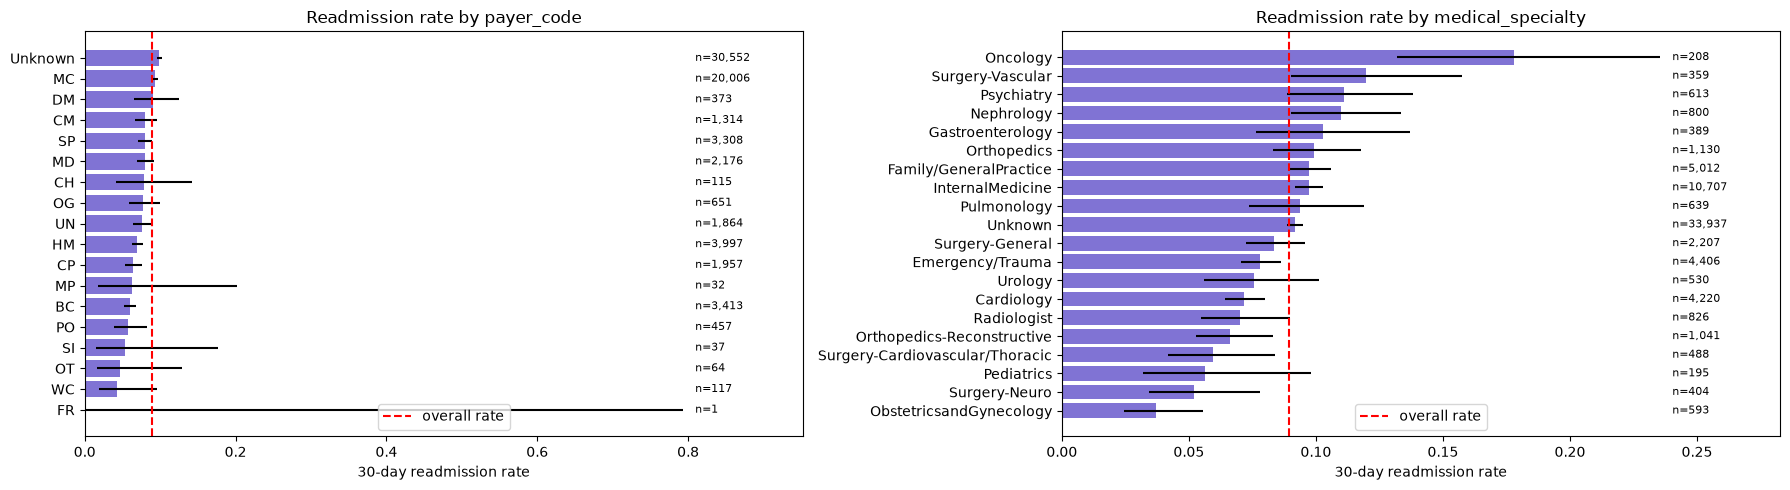

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, col in zip(axes, ADMIN_COLS):
    readmission_rate_by(df_clean, col, top_n=20, min_count=1, ax=ax)
plt.tight_layout()
plt.show()

#### Coded ID columns
These are numeric codes that encode categories.

In [80]:
for col in CODED_ID_COLS:
    print(f"{col}: {df_clean[col].nunique()} distinct codes")

admission_type_id: 8 distinct codes
discharge_disposition_id: 23 distinct codes
admission_source_id: 17 distinct codes


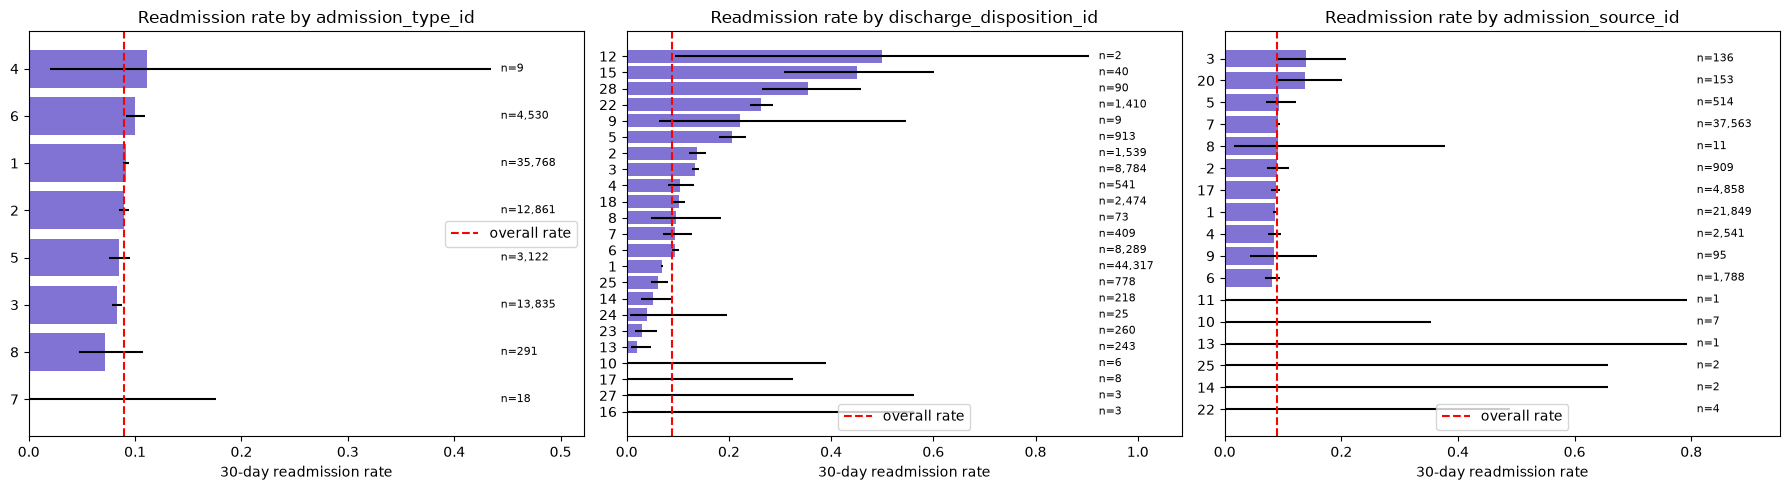

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, CODED_ID_COLS):
    readmission_rate_by(df_clean, col, top_n=25, min_count=1, ax=ax)
plt.tight_layout()
plt.show()

Most codes are too small to estimate a rate: a code with 50 patients has only about 4 readmissions, and its confidence interval is wider than any difference I could detect. A model would fit noise on those codes, and their SHAP values would be unstable

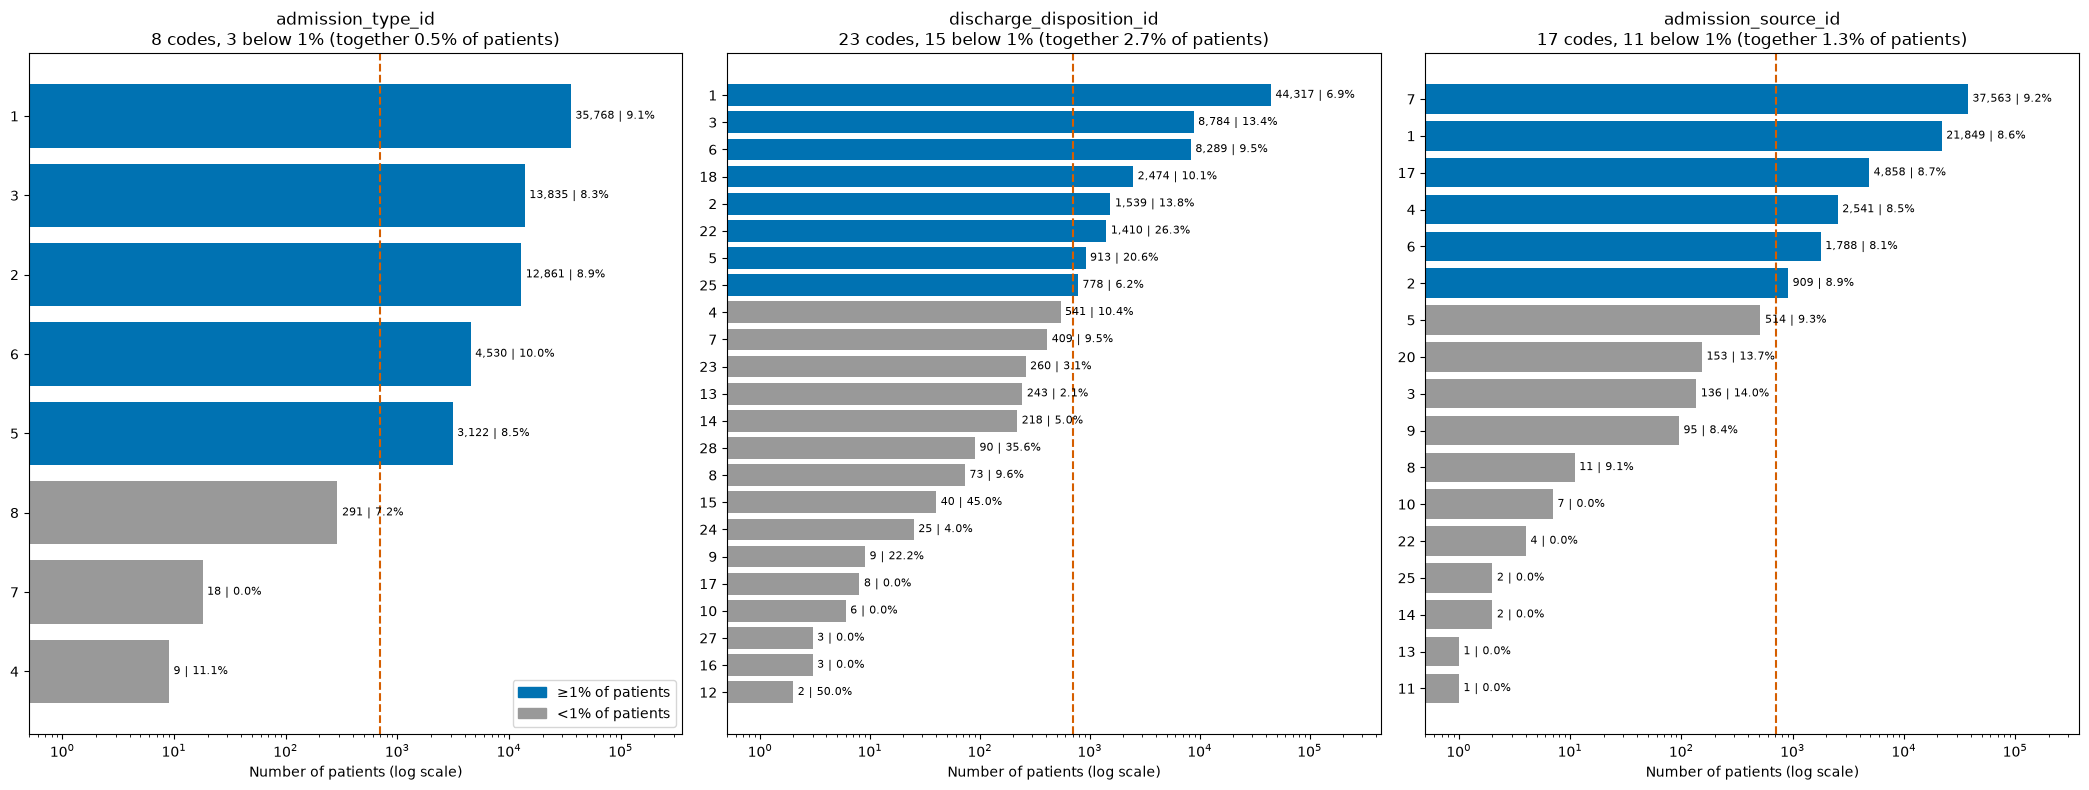

In [82]:
threshold = 0.01 * len(df_clean)

fig, axes = plt.subplots(1, 3, figsize=(21, 8))
for ax, col in zip(axes, CODED_ID_COLS):
    g = df_clean.groupby(col)[TARGET].agg(n="size", rate="mean").sort_values("n")
    rare = g["n"] < threshold
    ax.barh(g.index.astype(str), g["n"], color=["#999999" if r else "#0072B2" for r in rare])
    ax.set_xscale("log")
    ax.axvline(threshold, color="#D55E00", ls="--", lw=1.5)
    for i, (n, r) in enumerate(zip(g["n"], g["rate"])):
        ax.text(n * 1.1, i, f"{n:,} | {r:.1%}", va="center", fontsize=8)
    ax.set_xlim(0.5, g["n"].max() * 10)
    ax.set_xlabel("Number of patients (log scale)")
    ax.set_title(f"{col}\n{len(g)} codes, {rare.sum()} below 1% "
                 f"(together {g.loc[rare, 'n'].sum() / len(df_clean):.1%} of patients)")
axes[0].legend(handles=[Patch(color="#0072B2", label="≥1% of patients"),
                        Patch(color="#999999", label="<1% of patients")], loc="lower right")
plt.tight_layout()
plt.show()

**Should I drop the columns related to neonates so I only analyze adults?**

I will analyze the data and decided based on that. Neonates are usually more difficult to treat due to their smaller organs and not yet developed physiology

*discharge_disposition_id*

When checking `data/IDS_mapping.csv` we can see that when `discharge_disposition_id` is 10, it means that "Neonate discharged to another hospital for neonatal aftercare". I will now check how the target is distributed for this code:

In [35]:
df_clean[df_clean["discharge_disposition_id"] == 10][TARGET]

487     0
1027    0
1101    0
1585    0
1636    0
1983    0
Name: readmitted, dtype: int64

All cases are not readmitted in the next 30 days after their discharged. Let's have a look at the data:

In [36]:
df_clean[df_clean["discharge_disposition_id"] == 10]

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
487,4211154,86797872,Caucasian,Female,[70-80),6,10,7,9,Unknown,...,No,Steady,No,No,No,No,No,No,Yes,0
1027,7735086,48070035,Hispanic,Female,[70-80),6,10,7,8,Unknown,...,No,No,No,No,No,No,No,No,Yes,0
1101,8038050,46590138,Caucasian,Male,[60-70),6,10,1,8,Unknown,...,No,Up,No,No,No,No,No,Ch,Yes,0
1585,10741320,54373995,Caucasian,Female,[90-100),6,10,7,5,Unknown,...,No,No,No,No,No,No,No,No,No,0
1636,10987152,72268029,Caucasian,Female,[80-90),6,10,1,3,Unknown,...,No,No,No,No,No,No,No,No,Yes,0
1983,12839190,66062943,Caucasian,Male,[50-60),6,10,1,4,Unknown,...,No,No,No,No,No,No,No,No,Yes,0


The discharge disposition id refers to neonates; however, all patients with this discharged code are over 50. In addition, the `admission_type_id` for all cases is NULL and `payer_code` Unknown.

This pattern suggests administrative fields that were filled in badly or with default values, possibly from a single source that used a different coding system. Because this are only 6 rows, I will drop them

*admission_type_id*

When checking `data/IDS_mapping.csv` we can see that when `admission_type_id` 4 is associated with newborns. Let's check how the target is distributed for this code:

In [37]:
df_clean[df_clean["admission_type_id"] == 4][TARGET]

2043      0
2203      0
2461      0
4823      1
35877     0
47548     0
48711     0
80354     0
100721    0
Name: readmitted, dtype: int64

There is one patient that was readmitted. Let's see if the previous pattern can also be found for this code:

In [38]:
df_clean[df_clean["admission_type_id"] == 4]

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
2043,13169532,20191257,Caucasian,Male,[50-60),4,1,4,2,Unknown,...,No,Steady,No,No,No,No,No,No,Yes,0
2203,14369772,59902119,Caucasian,Male,[80-90),4,1,4,2,Unknown,...,No,Steady,No,No,No,No,No,No,Yes,0
2461,16168812,21564738,AfricanAmerican,Male,[70-80),4,6,4,5,Unknown,...,No,Up,No,No,No,No,No,Ch,Yes,0
4823,26323434,20593143,Caucasian,Female,[60-70),4,6,4,2,Unknown,...,No,Steady,No,No,No,No,No,No,Yes,1
35877,110766078,2177469,AfricanAmerican,Male,[60-70),4,1,14,3,UN,...,No,Steady,No,No,No,No,No,No,Yes,0
47548,146024844,58776723,Hispanic,Male,[40-50),4,1,7,6,CP,...,No,No,No,No,No,No,No,No,No,0
48711,148261332,217206,Caucasian,Female,[70-80),4,6,1,4,CP,...,No,No,No,No,No,No,No,Ch,Yes,0
80354,247730952,20103048,Hispanic,Female,[0-10),4,1,1,2,Unknown,...,No,No,No,No,No,No,No,No,No,0
100721,429690494,115019244,Asian,Male,[80-90),4,6,7,3,CM,...,No,No,No,No,No,No,No,No,Yes,0


All patients except one are over 40. I will dropped all this rows as well as the only case for the newborn as it appears to be the only case present and will not be representative.

*admission_source_id*

When checking `data/IDS_mapping.csv` we can see a few codes related to newborns:

| **admission_source_id** | **description** |
|---|---|
| 11 | Normal Delivery |
| 12 | Premature Delivery |
| 13 | Sick Baby |
| 14 | Extramural Birth |
| 23 | Born inside this hospital |
| 24 | Born outside this hospital |

In [39]:
df_clean[df_clean["admission_source_id"].isin([11, 12, 13, 14, 23, 24])]

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
35877,110766078,2177469,AfricanAmerican,Male,[60-70),4,1,14,3,UN,...,No,Steady,No,No,No,No,No,No,Yes,0
83432,261241218,65316006,AfricanAmerican,Female,[70-80),1,1,14,3,CM,...,No,No,No,No,No,No,No,No,No,0
83510,261714048,104860962,Caucasian,Female,[20-30),1,1,11,3,MD,...,No,Steady,No,No,No,No,No,No,Yes,0
97384,387908894,58461021,Caucasian,Male,[70-80),2,1,13,3,CM,...,No,No,No,No,No,No,No,No,Yes,0


There are only 4 patients with those codes and all are over 20. Therefore, I will also be dropping these rows.

#### Drug columns
Each drug describes what happened to it during the encounter: `No` means that it wasn't prescribes; `Steady`, `Up` and `Down` refer to how the dose was change or not.

I need to decide how I am going to encode these variables.

In [40]:
df_clean[DRUG_COLS[0]].unique()

<StringArray>
['No', 'Steady', 'Up', 'Down']
Length: 4, dtype: str

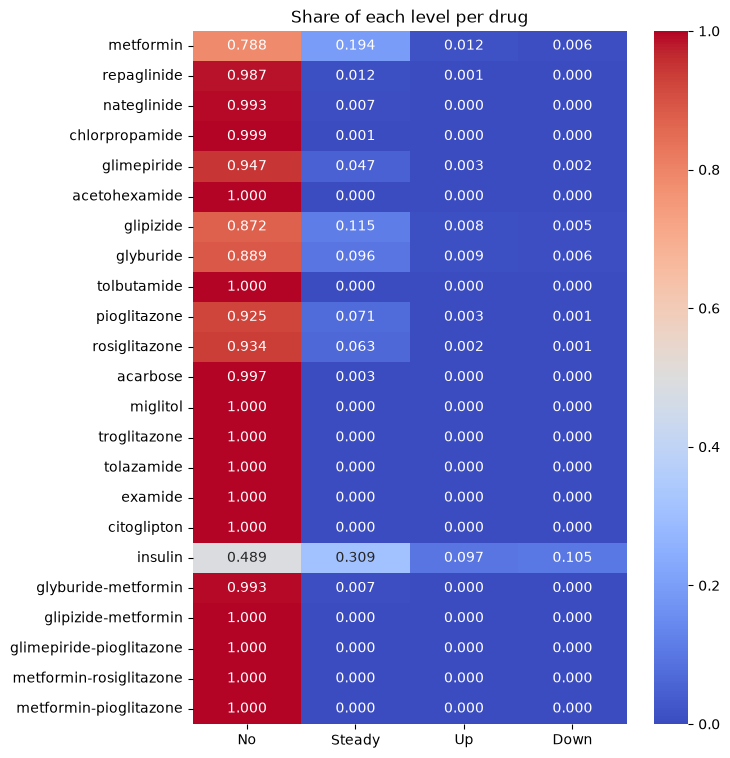

In [41]:
levels = ["No", "Steady", "Up", "Down"]
drug_levels = (
    pd.concat({c: df_clean[c].value_counts(normalize=True) for c in DRUG_COLS}, axis=1)
    .T.reindex(columns=levels).fillna(0)
)
fig, ax = plt.subplots(figsize=(7, 9))
sns.heatmap(drug_levels, annot=True, fmt=".3f", cmap="coolwarm", cbar=True, ax=ax)
ax.set_title("Share of each level per drug")
plt.show()

In [42]:
rare_drugs = sorted(drug_levels.index[drug_levels["No"] > 0.99].tolist())
print(f"{len(rare_drugs)} of the {len(DRUG_COLS)} drugs present in the dataset are prescribed in <1% of encounters:\n{rare_drugs}")

print(f"\nI am only keeping the following drugs:\n{sorted(set(DRUG_COLS) - set(rare_drugs))}")

15 of the 23 drugs present in the dataset are prescribed in <1% of encounters:
['acarbose', 'acetohexamide', 'chlorpropamide', 'citoglipton', 'examide', 'glimepiride-pioglitazone', 'glipizide-metformin', 'glyburide-metformin', 'metformin-pioglitazone', 'metformin-rosiglitazone', 'miglitol', 'nateglinide', 'tolazamide', 'tolbutamide', 'troglitazone']

I am only keeping the following drugs:
['glimepiride', 'glipizide', 'glyburide', 'insulin', 'metformin', 'pioglitazone', 'repaglinide', 'rosiglitazone']


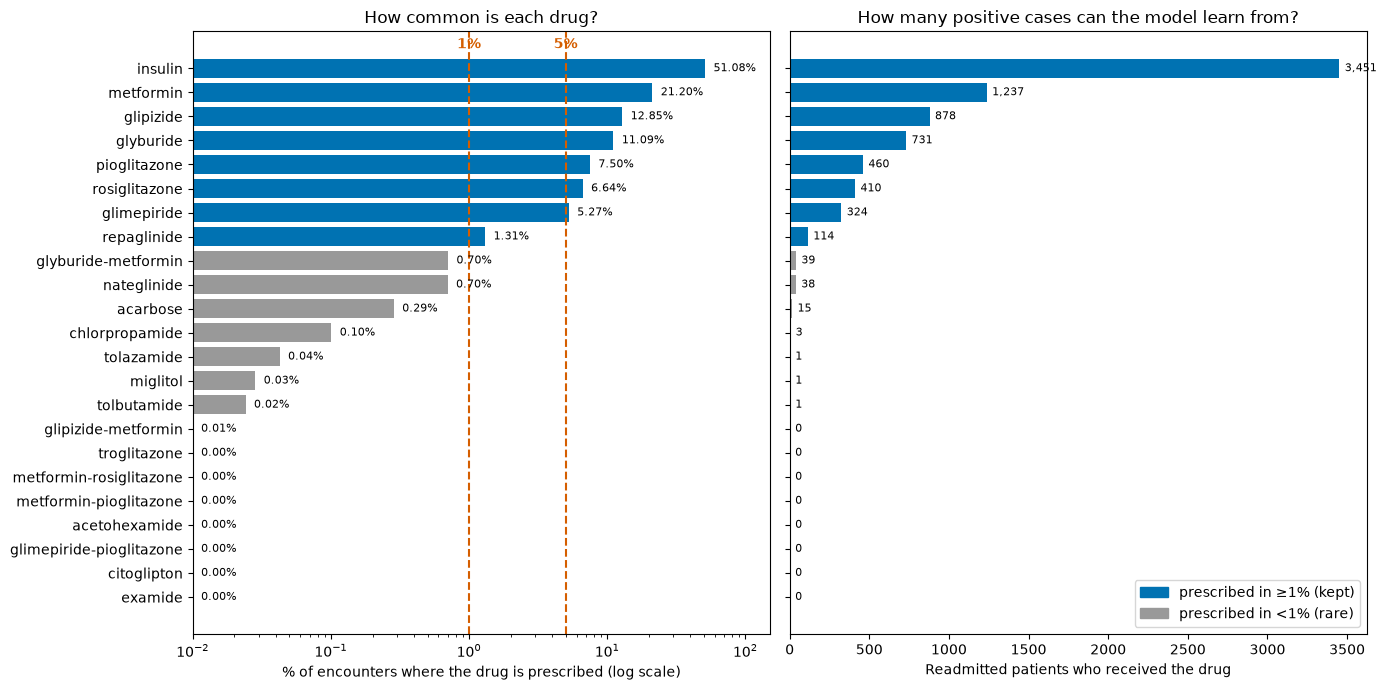

In [43]:
prescribed = df_clean[DRUG_COLS].ne("No")
prev = prescribed.mean().mul(100)
pos = prescribed[df_clean[TARGET] == 1].sum()
order = prev.sort_values().index
colors = ["#0072B2" if prev[d] >= 1 else "#999999" for d in order]   # blue = kept (>=1%), grey = rare

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

# Left: prevalence on a log scale, with the candidate thresholds
ax1.barh(order, prev[order].clip(lower=0.01), color=colors)
ax1.set_xscale("log")
ax1.set_xlim(0.01, 150)
for thr in (1, 5):
    ax1.axvline(thr, color="#D55E00", ls="--", lw=1.5)
    ax1.text(thr, len(order) - 0.3, f"{thr}%", color="#D55E00", ha="center", va="bottom", fontweight="bold")
for i, d in enumerate(order):
    ax1.text(max(prev[d], 0.01) * 1.15, i, f"{prev[d]:.2f}%", va="center", fontsize=8)
ax1.set_xlabel("% of encounters where the drug is prescribed (log scale)")
ax1.set_title("How common is each drug?")

# Right: readmitted patients who received the drug
ax2.barh(order, pos[order], color=colors)
for i, d in enumerate(order):
    ax2.text(pos[d] + pos.max() * 0.01, i, f"{pos[d]:,}", va="center", fontsize=8)
ax2.set_xlabel("Readmitted patients who received the drug")
ax2.set_title("How many positive cases can the model learn from?")
ax2.legend(handles=[Patch(color="#0072B2", label="prescribed in ≥1% (kept)"),
                    Patch(color="#999999", label="prescribed in <1% (rare)")], loc="lower right")

plt.tight_layout()
plt.show()

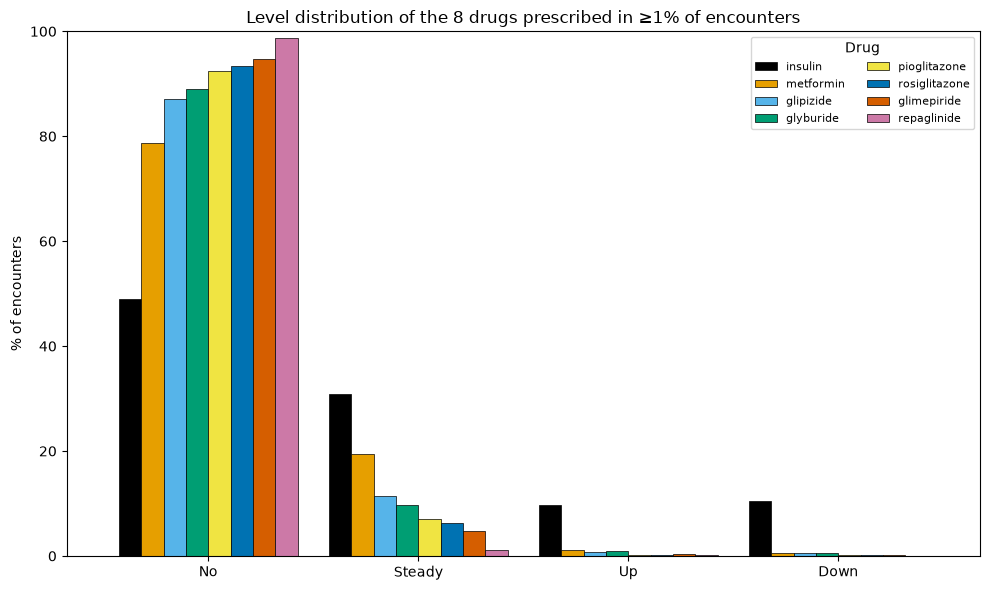

In [44]:
levels = ["No", "Steady", "Up", "Down"]
OKABE_ITO = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]

prev = df_clean[DRUG_COLS].ne("No").mean() * 100
kept = prev[prev >= 1].sort_values(ascending=False).index.tolist()  # drugs prescribed in >=1% of encounters

# rows = levels, columns = drugs, values = % of encounters
share = (pd.concat({d: df_clean[d].value_counts(normalize=True) for d in kept}, axis=1)
           .reindex(levels).fillna(0) * 100)

fig, ax = plt.subplots(figsize=(10, 6))
share.plot.bar(ax=ax, color=OKABE_ITO[:len(kept)], width=0.85, edgecolor="black", linewidth=0.5)
ax.set_ylim(0, 100)
ax.set_title(f"Level distribution of the {len(kept)} drugs prescribed in ≥1% of encounters")
ax.set_ylabel("% of encounters")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Drug", fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

The dataset has 23 drug columns with 4 levels each (`No`, `Steady`, `Up`, `Down`), which would become about 70 one-hot columns. Most are almost always `No`: 15 of the 23 drugs are prescribed in <1% of encounters, so their columns are nearly constant and would only add noise to the model.

Therefor, I will summarize all drugs in two features: 
- `n_drugs`: number of drugs prescribed in the encounter (value other than `No`).
- `n_dose_changes`: number of drugs whose dose went `Up` or `Down`.

In addition, I will drop the 15 drug columns that are rare and I will encode the other 8 columns based on their frequency as follows:
- `insulin` keeps its 4 levels, since it is by far the most common and its levels have different readmission rates.
- Other frequent drugs merge `Up` and `Down` into `Changed` (3 levels), because the separate levels are too small to learn from.

When analyzing the importance of the variables, I will need to take into account that `n_drugs` counts the individual drug columns, so SHAP importance may be shared between them.

#### Diagnoses
`diag_1` is the primary diagnosis, `diag_2` and `diag_3` are secondary. There are
hundreds of distinct ICD-9 codes, so they need to be grouped into clinical categories
(circulatory, respiratory, diabetes, injury, ...). Codes starting with `V` or `E`
are special (supplementary factors / external causes).

In [45]:
print({c: df_clean[c].nunique() for c in DIAG_COLS})

{'diag_1': 696, 'diag_2': 725, 'diag_3': 758}


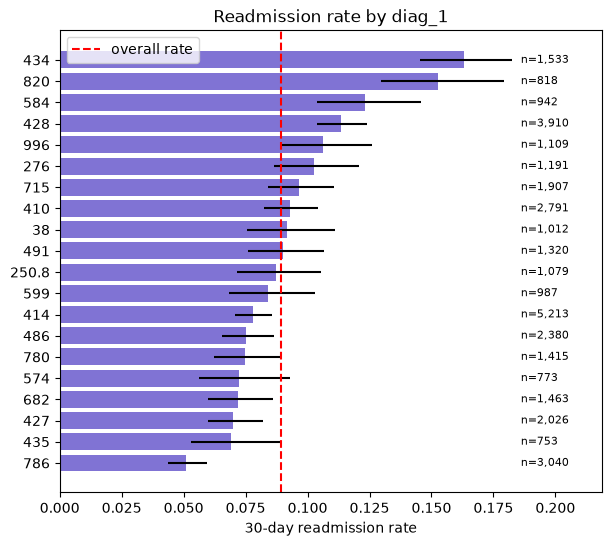

In [46]:
fig, ax = plt.subplots(figsize=(7, 6))
readmission_rate_by(df_clean, "diag_1", top_n=20, min_count=200, ax=ax)
plt.show()

#### Lab results

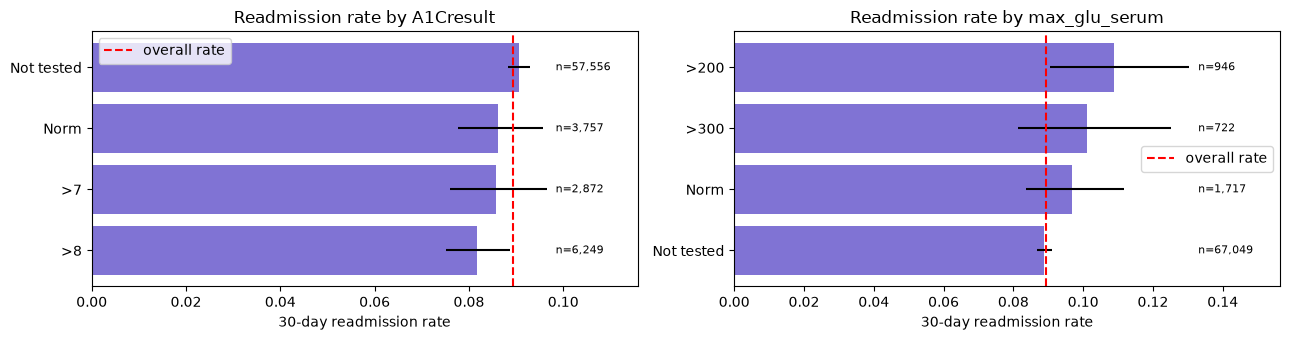

In [47]:
lab = df_clean.assign(
    A1Cresult=df_clean["A1Cresult"].fillna("Not tested"),
    max_glu_serum=df_clean["max_glu_serum"].fillna("Not tested"),
)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, col in zip(axes, ["A1Cresult", "max_glu_serum"]):
    readmission_rate_by(lab, col, ax=ax)
plt.tight_layout()
plt.show()

## Redundancy check

In [48]:
n_drugs = df_clean[DRUG_COLS].ne("No").sum(axis=1)
n_changes = df_clean[DRUG_COLS].isin(["Up", "Down"]).sum(axis=1)
print((df_clean["diabetesMed"].eq("Yes") == (n_drugs > 0)).all())
print((df_clean["change"].eq("Ch") == (n_changes > 0)).all())

True
False


## Summary of decisions and next steps
### Decisions taken
| Topic | Decision | Reason |
|---|---|---|
| Target | `readmitted == "<30"` -> binary | Task definition; ~8.94% positives after applying data leakage saveguards |
| Leakage 1 | Keep first encounter per patient | Avoid same patient in train and test and "future" information |
| Leakage 2 | Drop disposition IDs 11, 19, 20, 21 | These patients cannot be readmitted |
| Incorrect data | Drop disposition ID 10; admission type ID 4; admissions source IDs 11, 12, 13, 14, 23, 23| These patients are supposed to be newborns but all except one are over 20 |
| `weight` | Drop | ~97% missing |
| `max_glu_serum`, `A1Cresult` | Missing -> `"Not tested"` category | Missing means the test was not done |
| `payer_code`, `medical_specialty` | Missing -> `"Unknown"`, not dropped | Decide with evidence if they are relevant
| Drugs | `n_drugs` and `n_dose_changes` summarize information; rare drugs dropped; frequent but not insulin drugs will have 3 instead of 4 codes | Reduce number of sparse dummy variables |
| Diagnoses | Group ICS-9 into clinical categories | High cardinality |
| Metrics | ROC-AUC, PR-AUC, calibration | Imbalance |

### Next step
`src.preprocessing.py`: feature enginneering (drug aggregates, ICD-9 )